# Minimum embedding dimension: Cao's method, false nearest neighbours and Takens' bound

A delay embedding reconstructs an attractor from one scalar record $x(t)$ by the delay vectors

$$
\boldsymbol{y}_i(d) = \left( x_i,\ x_{i+\zeta},\ \dots,\ x_{i+(d-1)\zeta} \right) \in \mathbb{R}^d ,
$$

where $\zeta$ is the delay (in samples) and $d$ the embedding dimension. If $d$ is too small, the
reconstruction folds the attractor onto itself; if $d$ is too large, the reconstruction wastes data
and amplifies noise. This notebook compares three ways of choosing $d$, all in `ntsa.tools`:

| Function | Method | What it returns |
| --- | --- | --- |
| `cao_embedding_dimension(x, lag, ...)` | Cao (1997): saturation of $E_1(d)$ | estimated minimum dimension, $E_1(d)$, $E_2(d)$ |
| `false_nearest_neighbours(x, lag, ...)` | Kennel, Brown & Abarbanel (1992) | estimated minimum dimension, false-neighbour fractions |
| `takens_bound(D)` | Takens (1981); Sauer, Yorke & Casdagli (1991) | upper bound $\lfloor 2D + 1 \rfloor$, the dimension $D$ |

The first two estimate the minimum embedding dimension $m_\mathrm{min}$ from the data. The third
bounds it from the dimension $D$ of the system: Takens' theorem guarantees an embedding for every
$m \ge 2D + 1$, so

$$
D < m_\mathrm{min} \le \lfloor 2D + 1 \rfloor ,
$$

where the lower bound holds because the reconstruction must contain the attractor. The bound is a
sufficient condition, so the data-driven estimates typically lie below it. We test the three on
Lorenz-63, one site of Lorenz-96 and white noise, and then analyse how the estimates depend on the
length of the series and on observation noise.

In [1]:
# ruff: noqa: E402, I001  (the BLAS pinning must run before numpy is imported)
import os
for var in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(var, '1')

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from ntsa import tools as ntsa_tools
from dynamodels.physical import Lorenz63, Lorenz96

# Paul Tol 'bright' palette (colour-blind safe), one colour per method
C_CAO, C_FNN, C_TAK, C_GREY = '#4477AA', '#EE6677', '#228833', '#BBBBBB'
D_MAX = 12

## 1. Cao's method

For each delay vector $\boldsymbol{y}_i(d)$, let $\boldsymbol{y}_{n(i,d)}(d)$ be its nearest
neighbour in the maximum norm, excluding temporal neighbours $\lvert i - n \rvert \le w$ (the
Theiler window $w$). Cao (1997) measures how much the neighbour distance grows when the
$(d+1)$-th coordinate is added,

$$
a(i, d) = \frac{\lVert \boldsymbol{y}_i(d+1) - \boldsymbol{y}_{n(i,d)}(d+1) \rVert_\infty}
               {\lVert \boldsymbol{y}_i(d) - \boldsymbol{y}_{n(i,d)}(d) \rVert_\infty},
\qquad
E(d) = \langle a(i, d) \rangle_i,
\qquad
E_1(d) = \frac{E(d+1)}{E(d)} ,
$$

where $\langle \cdot \rangle_i$ is the average over the reference points. False neighbours make
$a(i,d)$ large; once $d$ unfolds the attractor, adding a coordinate no longer changes the
neighbourhoods and $E_1(d)$ stops changing. `cao_embedding_dimension` returns the first $d$ at
which successive values of $E_1$ differ by less than a tolerance `tol`. Unlike false nearest
neighbours, the method has no distance threshold to choose.

Because $E_1$ also saturates for random data, Cao defines a second quantity from the added
coordinate alone,

$$
E^*(d) = \langle \lvert x_{i+d\zeta} - x_{n(i,d)+d\zeta} \rvert \rangle_i,
\qquad
E_2(d) = \frac{E^*(d+1)}{E^*(d)} .
$$

For random data the future value does not depend on the past, so $E_2(d) \approx 1$ for every
$d$. For deterministic data $E_2(d)$ departs from 1 at small $d$, where close neighbours have
close futures.

## 2. Test cases

We integrate Lorenz-63 ($\rho = 28$) and Lorenz-96 ($N_x = 10$, $F = 8$) with `run_long`, record
the first state component of each, and generate Gaussian white noise of comparable length. The
delay is the first minimum of the average mutual information (`optimal_lag`), and the Theiler
window is one delay.

In [2]:
l63 = Lorenz63(dt=0.01)
l96 = Lorenz96(Nx=10, F=8., dt=0.01)
_, y63, _ = ntsa_tools.run_long(ntsa_tools.respawn(l63), t_run=300 * l63.t_lyap)
_, y96, _ = ntsa_tools.run_long(ntsa_tools.respawn(l96), t_run=400 * l96.t_lyap)
rng = np.random.default_rng(0)

cases = {
    'Lorenz-63, $x$': dict(x=y63[:, 0], model=l63),
    'Lorenz-96, $x_1$': dict(x=y96[:, 0], model=l96),
    'white noise': dict(x=rng.standard_normal(len(y63)), model=None),
}
for name, c in cases.items():
    m = c['model']
    c['lag'] = ntsa_tools.optimal_lag(c['x'], max_lag=int(m.t_CR / m.dt)) if m else 1
    print(f"{name:18s} N = {len(c['x'])}, lag = {c['lag']} samples")

Lorenz-63, $x$     N = 32716, lag = 16 samples


Lorenz-96, $x_1$   N = 33785, lag = 39 samples
white noise        N = 32716, lag = 1 samples


## 3. Estimates and bounds

For each case we compute $E_1$, $E_2$ and the false-neighbour fraction for $d = 1, \dots, 12$.
For Takens' bound we need $D$, which we take in two ways. The first is the Kaplan-Yorke dimension
$D_\mathrm{KY}$ of the Lyapunov spectrum (`lyapunov_spectrum`, `kaplan_yorke`), which estimates
the attractor dimension from the equations and corresponds to the box-counting reading of
Sauer, Yorke & Casdagli (1991). The second is the correlation dimension $D_2$ of the delay
embedding (`correlation_dimension`), which `takens_bound` computes when it receives the series
instead of $D$; this is the only option for measured data. We also report Takens' original
reading, in which $D$ is the dimension of the state space that contains the dynamics. White noise
has no finite-dimensional attractor, so only the estimate from the series applies.

The correlation dimension of the delay embedding at increasing $d$ is a fourth, classical
diagnostic: for a deterministic attractor $D_2$ saturates once $d$ unfolds it, whereas for noise
it keeps growing with $d$.

In [3]:
for name, c in cases.items():
    x, lag, m = c['x'], c['lag'], c['model']
    c['d_cao'], c['E1'], c['E2'] = ntsa_tools.cao_embedding_dimension(x, lag, d_max=D_MAX, theiler=lag)
    c['d_fnn'], c['fnn'] = ntsa_tools.false_nearest_neighbours(x, lag, d_max=D_MAX)
    c['D2_d'] = np.array([ntsa_tools.correlation_dimension(ntsa_tools.delay_embed(x, d, lag))[0]
                          for d in range(1, D_MAX + 1)])
    c['bound_D2'], c['D2'] = ntsa_tools.takens_bound(x=x, lag=lag, d_embed=c['d_cao'])
    if m is not None:
        c['D_KY'] = ntsa_tools.kaplan_yorke(ntsa_tools.lyapunov_spectrum(ntsa_tools.respawn(m), verbose=False))
        c['bound_KY'], _ = ntsa_tools.takens_bound(c['D_KY'])
        c['bound_state'], _ = ntsa_tools.takens_bound(m.Nphi)

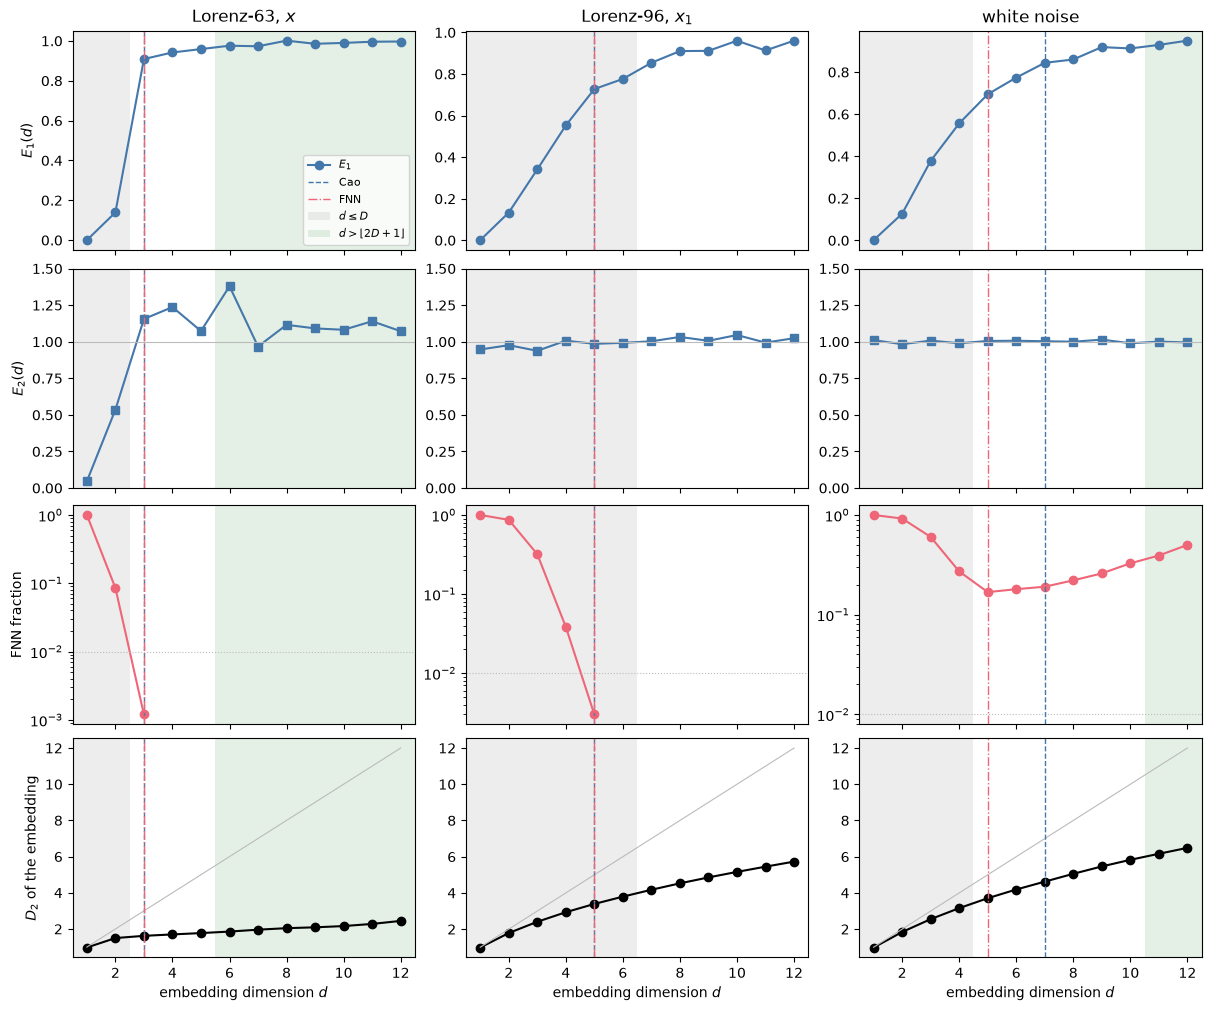

In [4]:
dims = np.arange(1, D_MAX + 1)
fig, axs = plt.subplots(4, 3, figsize=(12, 10), sharex=True, layout='constrained')
for col, (name, c) in enumerate(cases.items()):
    ax = axs[0, col]
    ax.plot(dims, c['E1'], 'o-', color=C_CAO, label='$E_1$')
    ax.set_title(name)
    ax = axs[1, col]
    ax.plot(dims, c['E2'], 's-', color=C_CAO, label='$E_2$')
    ax.axhline(1, color=C_GREY, lw=0.8)
    ax.set_ylim(0, 1.5)
    ax = axs[2, col]
    ax.semilogy(dims, np.where(c['fnn'] > 0, c['fnn'], np.nan), 'o-', color=C_FNN)
    ax.axhline(0.01, color=C_GREY, lw=0.8, ls=':')
    ax = axs[3, col]
    ax.plot(dims, c['D2_d'], 'o-', color='k')
    ax.plot(dims, dims, color=C_GREY, lw=0.8)
    for row in range(4):
        a = axs[row, col]
        a.axvline(c['d_cao'], color=C_CAO, ls='--', lw=1, label='Cao' if row == 0 else None)
        a.axvline(c['d_fnn'], color=C_FNN, ls='-.', lw=1, label='FNN' if row == 0 else None)
        D, bound = c.get('D_KY', c['D2']), c.get('bound_KY', c['bound_D2'])
        a.axvspan(0.5, np.floor(D) + 0.5, color=C_GREY, alpha=0.25, lw=0,
                  label=r'$d \leq D$' if row == 0 else None)
        a.axvspan(bound + 0.5, D_MAX + 0.5, color=C_TAK, alpha=0.12, lw=0,
                  label=r'$d > \lfloor 2D+1 \rfloor$' if row == 0 else None)
    axs[3, col].set_xlabel('embedding dimension $d$')
    axs[3, col].set_xlim(0.5, D_MAX + 0.5)
axs[0, 0].set_ylabel('$E_1(d)$')
axs[1, 0].set_ylabel('$E_2(d)$')
axs[2, 0].set_ylabel('FNN fraction')
axs[3, 0].set_ylabel('$D_2$ of the embedding')
axs[0, 0].legend(fontsize=8, loc='lower right');

*Rows from top to bottom: Cao's $E_1(d)$ and $E_2(d)$, the false-neighbour fraction (dotted:
1% threshold), and the correlation dimension of the delay embedding (grey: $D_2 = d$). Dashed and
dash-dotted lines mark the dimensions estimated by Cao's method and by false nearest neighbours;
the grey band marks dimensions $d \le D$, which cannot contain the attractor, and the green band
dimensions beyond Takens' bound, with $D = D_\mathrm{KY}$ for the two Lorenz systems and $D = D_2$
(from the series) for noise.*

For the deterministic cases, $E_2$ departs from 1 at small $d$ and $D_2$ levels off; for noise,
$E_2$ stays at 1 and $D_2$ keeps growing with $d$. The table below collects the estimates and the
bounds, and checks whether each estimate lies in $(D, \lfloor 2D+1 \rfloor]$ with $D = D_\mathrm{KY}$
(or $D_2$ for noise).

In [5]:
rows = []
print(f"{'case':18s} {'Cao':>4s} {'FNN':>4s} {'E2 flat':>8s} {'D_KY':>6s} {'D2':>6s} "
      f"{'bound(state)':>12s} {'bound(D_KY)':>11s} {'bound(D2)':>9s}")
for name, c in cases.items():
    c['e2_flat'] = bool(np.all(np.abs(c['E2'] - 1) < 0.1))
    D_ky = c.get('D_KY', np.nan)
    print(f"{name:18s} {c['d_cao']:4d} {c['d_fnn']:4d} {str(c['e2_flat']):>8s} {D_ky:6.2f} {c['D2']:6.2f} "
          f"{c.get('bound_state', '-'):>12} {c.get('bound_KY', '-'):>11} {c['bound_D2']:9d}")

print()
for name, c in cases.items():
    print(f"{name}: E2 {'stays within 0.1 of 1 for every d (reads as stochastic)' if c['e2_flat'] else 'departs from 1 (deterministic)'}")
    if 'D_KY' not in c:
        continue
    D, bound = c['D_KY'], c['bound_KY']
    for method in ('cao', 'fnn'):
        d = c[f'd_{method}']
        side = 'inside' if D < d <= bound else ('below D_KY: too few points to unfold the attractor' if d <= D
                                                else 'above the bound')
        print(f"    {method.upper()} d = {d} vs (D_KY, 2 D_KY + 1] = ({D:.2f}, {bound}] -> {side}")

case                Cao  FNN  E2 flat   D_KY     D2 bound(state) bound(D_KY) bound(D2)
Lorenz-63, $x$        3    3    False   2.06   1.62            7           5         4
Lorenz-96, $x_1$      5    5     True   6.47   3.39           21          13         7
white noise           7    5     True    nan   4.62            -           -        10

Lorenz-63, $x$: E2 departs from 1 (deterministic)
    CAO d = 3 vs (D_KY, 2 D_KY + 1] = (2.06, 5] -> inside
    FNN d = 3 vs (D_KY, 2 D_KY + 1] = (2.06, 5] -> inside
Lorenz-96, $x_1$: E2 stays within 0.1 of 1 for every d (reads as stochastic)
    CAO d = 5 vs (D_KY, 2 D_KY + 1] = (6.47, 13] -> below D_KY: too few points to unfold the attractor
    FNN d = 5 vs (D_KY, 2 D_KY + 1] = (6.47, 13] -> below D_KY: too few points to unfold the attractor
white noise: E2 stays within 0.1 of 1 for every d (reads as stochastic)


The verdicts answer three questions: whether $E_2$ reads the series as stochastic, whether
the two data-driven estimates agree, and whether they lie in $(D, \lfloor 2D+1 \rfloor]$. For a
low-dimensional attractor such as Lorenz-63, both estimates are expected inside the interval and
below the bound from the state dimension: the bound guarantees an embedding but does not find the
smallest one. For a high-dimensional attractor, the number of points needed to populate the
neighbourhoods grows exponentially with the dimension, so a finite record can give estimates below
$D_\mathrm{KY}$ (Kantz & Schreiber 2004, ch. 9); the lower end of the interval exposes this. The
correlation dimension of the embedding is low for the same reason, and so is the bound that
`takens_bound` computes from the series.

$E_2$ also loses contrast on high-dimensional chaos (Cao 1997). When the delay is long compared
with the predictability time, the added coordinates of close neighbours decorrelate and $E_2$
approaches 1, although the series is deterministic. The next cell repeats $E_2$ for Lorenz-96 at
a quarter of the delay.

In [6]:
c96 = cases['Lorenz-96, $x_1$']
lag_short = max(1, c96['lag'] // 4)
_, _, E2_short = ntsa_tools.cao_embedding_dimension(c96['x'], lag_short, d_max=D_MAX, theiler=lag_short)
for lag, E2 in ((c96['lag'], c96['E2']), (lag_short, E2_short)):
    flat = np.all(np.abs(E2 - 1) < 0.1)
    print(f"Lorenz-96, lag = {lag:2d}: min E2 = {E2.min():.2f} -> {'stochastic-looking' if flat else 'deterministic'}")

Lorenz-96, lag = 39: min E2 = 0.94 -> stochastic-looking
Lorenz-96, lag =  9: min E2 = 0.52 -> deterministic


## 4. Dependence on the length of the series

We repeat the Lorenz-63 estimates on the first $N$ samples of the record, at fixed delay, and
print the shortest record from which each estimate no longer changes. Lorenz-63 is low-dimensional,
so a few Lyapunov times of data are expected to suffice; the Lorenz-96 result of section 3 shows
that this does not carry over to high-dimensional attractors.

In [7]:
x63, lag63 = cases['Lorenz-63, $x$']['x'], cases['Lorenz-63, $x$']['lag']
Ns = np.array([250, 500, 1000, 2000, 5000, 10000, 20000])
d_cao_N = [ntsa_tools.cao_embedding_dimension(x63[:N], lag63, theiler=lag63)[0] for N in Ns]
d_fnn_N = [ntsa_tools.false_nearest_neighbours(x63[:N], lag63)[0] for N in Ns]
for N, a, b in zip(Ns, d_cao_N, d_fnn_N):
    print(f"N = {N:6d} ({N * l63.dt / l63.t_lyap:6.1f} t_lyap): Cao {a}, FNN {b}")
for name, ds in (('Cao', d_cao_N), ('FNN', d_fnn_N)):
    k = len(ds) - 1
    while k > 0 and ds[k - 1] == ds[-1]:
        k -= 1
    print(f"{name}: constant at d = {ds[-1]} for N >= {Ns[k]} ({Ns[k] * l63.dt / l63.t_lyap:.1f} t_lyap)")

N =    250 (   2.3 t_lyap): Cao 2, FNN 2
N =    500 (   4.6 t_lyap): Cao 3, FNN 3
N =   1000 (   9.2 t_lyap): Cao 3, FNN 3
N =   2000 (  18.3 t_lyap): Cao 3, FNN 3
N =   5000 (  45.9 t_lyap): Cao 3, FNN 3
N =  10000 (  91.7 t_lyap): Cao 3, FNN 3
N =  20000 ( 183.4 t_lyap): Cao 3, FNN 3
Cao: constant at d = 3 for N >= 500 (4.6 t_lyap)
FNN: constant at d = 3 for N >= 500 (4.6 t_lyap)


## 5. Dependence on observation noise

We add Gaussian noise of standard deviation $\eta\,\sigma_x$ to the Lorenz-63 record, in which
$\sigma_x$ is the standard deviation of the signal and $\eta$ the relative noise level. At the
scale of the noise the data fill every dimension, so the neighbour statistics drift towards those
of a stochastic series.

eta = 0.000: Cao (tol 0.05) 3, Cao (tol 0.1) 3, FNN 3
eta = 0.005: Cao (tol 0.05) 5, Cao (tol 0.1) 3, FNN 3
eta = 0.010: Cao (tol 0.05) 4, Cao (tol 0.1) 3, FNN 3
eta = 0.020: Cao (tol 0.05) 5, Cao (tol 0.1) 4, FNN 4
eta = 0.050: Cao (tol 0.05) 5, Cao (tol 0.1) 5, FNN 4
eta = 0.100: Cao (tol 0.05) 5, Cao (tol 0.1) 5, FNN 5
eta = 0.200: Cao (tol 0.05) 5, Cao (tol 0.1) 5, FNN 6
Cao, tol 0.05 : estimate first leaves its noiseless value at eta = 0.005
Cao, tol 0.1  : estimate first leaves its noiseless value at eta = 0.02
FNN           : estimate first leaves its noiseless value at eta = 0.02


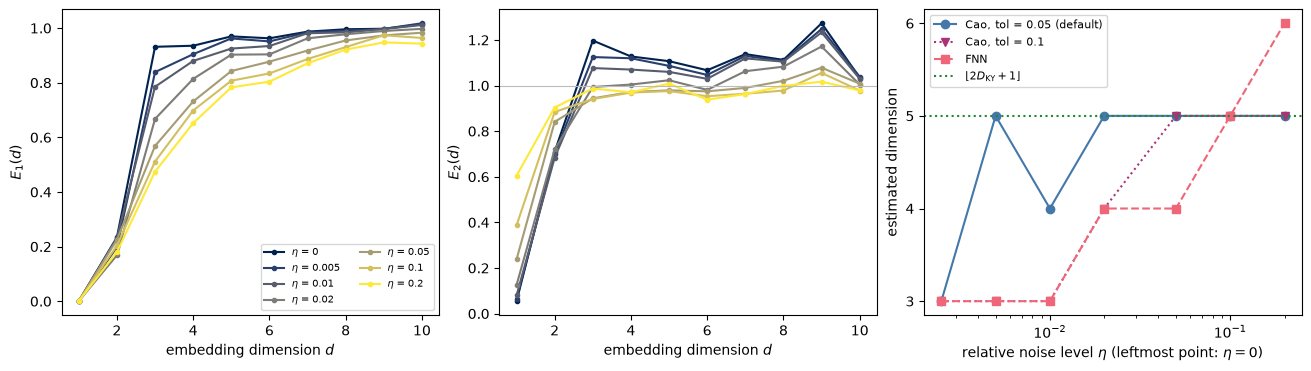

In [8]:
etas = np.array([0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
N_noise = 10000
rng = np.random.default_rng(1)
noisy = {eta: x63[:N_noise] + eta * x63.std() * rng.standard_normal(N_noise) for eta in etas}
res = {eta: ntsa_tools.cao_embedding_dimension(xn, lag63, theiler=lag63) for eta, xn in noisy.items()}
d_fnn_eta = [ntsa_tools.false_nearest_neighbours(noisy[eta], lag63)[0] for eta in etas]
d_cao_eta = [res[eta][0] for eta in etas]
d_cao_eta_loose = [ntsa_tools.cao_embedding_dimension(xn, lag63, theiler=lag63, tol=0.1)[0]
                   for xn in noisy.values()]

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), layout='constrained')
cmap = plt.get_cmap('cividis')
for k, eta in enumerate(etas):
    col = cmap(k / (len(etas) - 1))
    axs[0].plot(dims[:10], res[eta][1], 'o-', ms=3, color=col, label=rf'$\eta$ = {eta:g}')
    axs[1].plot(dims[:10], res[eta][2], 'o-', ms=3, color=col)
axs[0].set(xlabel='embedding dimension $d$', ylabel='$E_1(d)$')
axs[1].axhline(1, color=C_GREY, lw=0.8)
axs[1].set(xlabel='embedding dimension $d$', ylabel='$E_2(d)$')
axs[0].legend(fontsize=7, ncol=2)
x_eta = np.where(etas > 0, etas, etas[1] / 2)  # noiseless case drawn at the left edge
axs[2].semilogx(x_eta, d_cao_eta, 'o-', color=C_CAO, label='Cao, tol = 0.05 (default)')
axs[2].semilogx(x_eta, d_cao_eta_loose, 'v:', color='#AA3377', label='Cao, tol = 0.1')
axs[2].semilogx(x_eta, d_fnn_eta, 's--', color=C_FNN, label='FNN')
axs[2].yaxis.get_major_locator().set_params(integer=True)
axs[2].axhline(cases['Lorenz-63, $x$']['bound_KY'], color=C_TAK, ls=':', label=r'$\lfloor 2D_\mathrm{KY}+1 \rfloor$')
axs[2].set(xlabel=r'relative noise level $\eta$ (leftmost point: $\eta = 0$)', ylabel='estimated dimension')
axs[2].legend(fontsize=8);

for eta, a, a2, b in zip(etas, d_cao_eta, d_cao_eta_loose, d_fnn_eta):
    print(f"eta = {eta:5.3f}: Cao (tol 0.05) {a}, Cao (tol 0.1) {a2}, FNN {b}")
for name, ds in (('Cao, tol 0.05', d_cao_eta), ('Cao, tol 0.1', d_cao_eta_loose), ('FNN', d_fnn_eta)):
    first = next((eta for eta, d in zip(etas, ds) if d != ds[0]), None)
    print(f"{name:14s}: estimate first leaves its noiseless value at eta = {first}")

*Lorenz-63 with observation noise. Left and centre: $E_1(d)$ and $E_2(d)$ at increasing relative
noise level $\eta$. Right: the dimension estimated by Cao's method with two saturation tolerances and by
false nearest neighbours, with Takens' bound from $D_\mathrm{KY}$ (dotted).*

Noise slows the approach of $E_1$ to its plateau, so the saturation test on $E_1$ reports a
larger dimension, and it pulls $E_2$ towards 1, the signature of a stochastic series. False
nearest neighbours degrades too, because the noise displaces neighbours along the added coordinate
and the distance threshold $R_\mathrm{tol}$ then flags them as false. The printed verdict compares
how soon each estimate leaves its noiseless value. A larger tolerance in the saturation test makes
Cao's estimate less sensitive to noise, at the price of stopping earlier on curves that are still
rising; denoising before the embedding is the alternative.

## 6. Summary

- Cao's $E_1$ and false nearest neighbours estimate the minimum embedding dimension from the data;
  Cao's method needs no distance threshold, and its $E_2$ separates deterministic from stochastic
  series, which false nearest neighbours cannot do.
- Takens' bound $\lfloor 2D + 1 \rfloor$ is a sufficient condition from the dimension of the
  system. It bounds the minimum embedding dimension from above, so it is a consistency check on
  the estimates rather than an estimate.
- On a high-dimensional attractor, a finite record can make both nearest-neighbour methods
  underestimate the dimension, and a long delay can make $E_2$ read deterministic chaos as noise;
  the check $D < m_\mathrm{min}$ and a shorter delay expose both.

**References.** Cao (1997), *Physica D* 110, 43. Kennel, Brown & Abarbanel (1992), *Phys. Rev. A*
45, 3403. Takens (1981), *Lecture Notes in Math.* 898, 366. Sauer, Yorke & Casdagli (1991),
*J. Stat. Phys.* 65, 579. Kantz & Schreiber (2004), *Nonlinear Time Series Analysis*, CUP.